# The held-out models and the controls: where the calibrated model has skill and where it does not

**Question:** For which of the two measured targets does the held-out calibrated model beat the constant-mean baseline, and does the residual model that adds free parameters on top of it learn anything that a label-shuffle control does not?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- fit the calibrated model, the bounded-residual model, the free-form regression and the constant mean fold by fold for the throughput and for the power, with CrusherCal's public functions;
- apply the constant-mean baseline and say for which target the calibrated model beats it;
- read the bounded residual before and after its clip, and read the residual model as the pre-registered null it is;
- run the label-shuffle control over many seeds, and say what it tests: the residual model, not the skill of the calibrated model.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the engine with its calibrated lane and Bond power, and the CrusherCal module.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import HP500_QREF, bond_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
from pipeline.hp500 import loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. File read: `data/examples/hp500-surveys.csv`. The two measured targets are the throughput in t/h and the power in kW; the product size is a model output, so it is not a target here.

The cell reads the table and keeps the two measured targets and the two regressors of the free-form model, the setting and the f80.

In [2]:
# Read the survey table and keep the two measured targets and the regressors, the setting and the f80
surveys = read_surveys().accepted
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
targets = {"tph": measured_q, "kW": measured_kw}
print("surveys:", len(surveys), "| throughput range [t/h]:", measured_q.min(), measured_q.max())
print("power range [kW]:", measured_kw.min(), measured_kw.max())

surveys: 10 | throughput range [t/h]: 813.0 1639.0
power range [kW]: 187.0 355.0


## Method

**Step 1, the inputs of the two calibrated models.** CrusherCal's model M0 is the engine's physics with its global scalars refitted in every fold. For the throughput it is $Q = Q_T\,s_i$, with $s_i$ the engine's capacity factor at survey $i$ (its throughput over the paper's base of 647 t/h) and $Q_T$ the one refitted scalar. For the power it is the paper's form $P_c = \zeta\,P_d + P_n$ (Rocha et al., 2024; https://doi.org/10.3390/min14090919), with $P_d$ the engine's Bond power and the two coefficients refitted. The cell runs the engine at the ten surveys and prints the two inputs.

In [3]:
# The inputs of the two backbones, to 0.01 as the committed documents carry them: capacity factor, Bond power
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
shape = np.array([r.throughput_tph for r in runs]).round(2) / HP500_QREF
bond_kw = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs]).round(2)
print("capacity factor by survey:", shape.round(3))
print("Bond power by survey [kW]:", bond_kw.round(1))

capacity factor by survey: [1.868 1.868 1.711 1.711 1.711 1.5   1.447 1.605 1.5   1.895]
Bond power by survey [kW]: [229.5 233.7 224.9 225.7 234.8 222.5 196.1 212.7 221.6 237.5]


**Step 2, the strict folds.** In each of the ten folds the cell refits the scalars of M0 on nine surveys (`fit_capacity_base`, `fit_power_form`), refits the free-form regression M2 on the setting and the f80 (`fit_freeform`), and takes the mean of the nine as the baseline. M2 has no physics and three coefficients per target, the overfit strawman that the protocol expects to lose. The cell prints how the refitted scalars move from fold to fold.

In [4]:
# The ten strict folds and, in each, the calibrated model M0, the free-form M2 and the constant mean
folds = [loo.fold_indices(10, i, leaky=False) for i in range(10)]
qt = [loo.fit_capacity_base(shape, measured_q, rows) for rows in folds]
power_form = [loo.fit_power_form(bond_kw, measured_kw, rows) for rows in folds]
pred = {("tph", "M0"): np.array([loo.predict_capacity(q, shape, i) for i, q in enumerate(qt)]),
        ("kW", "M0"): np.array([z * bond_kw[i] + pn for i, (z, pn) in enumerate(power_form)])}
for key, y in targets.items():
    free = [loo.fit_freeform(features, y, rows) for rows in folds]
    pred[key, "M2"] = np.array([loo.predict_freeform(c, features[i]) for i, c in enumerate(free)])
    pred[key, "mean"] = np.array([y[rows].mean() for rows in folds])
print("capacity base per fold [t/h]:", np.round(qt, 1))
print("power form, zeta per fold:", np.round([z for z, _ in power_form], 2))
print("power form, Pn per fold [kW]:", np.round([pn for _, pn in power_form], 1))

capacity base per fold [t/h]: [659.3 687.1 681.5 695.3 689.3 698.3 682.9 683.7 697.9 683.4]
power form, zeta per fold: [-2.1  -1.95 -2.4  -2.51 -3.05 -2.34 -5.56 -2.31 -2.31 -1.5 ]
power form, Pn per fold [kW]: [ 766.   731.   827.   842.8  962.5  805.  1547.   804.1  797.8  633.8]


The capacity base moves between 659 and 698 t/h from fold to fold, as in notebook 01, and the throughput model stays a one-parameter fit. The power form does not behave as a physical coefficient should. In all ten folds $\zeta$ comes out negative, from -5.56 to -1.5, where the paper's own value is +1.30, and $P_n$ swings from 634 to 1547 kW to compensate. The measured power falls as the setting opens while the engine's Bond power rises with it (the table of notebook 02 of topic 05), so a least-squares line through the Bond power takes a negative slope, and the fold without survey 7 (setting 38 mm, the lowest Bond power, 196 kW, with a measured 306 kW) is the extreme at -5.56. A coefficient with the opposite sign of the physics it stands for means the form predicts through its intercept, and that is the thing to remember when the power scores come out.

**Step 3, the bounded residual.** The residual model M1 is the pre-registered proposal of CrusherCal: a ridge regression (penalty 1) of the residual of M0 on the standardized setting and f80, fitted on the nine training surveys and added to M0, with its value clipped to plus or minus 20 percent of M0 so that it stays a physical correction and not a second model. The cell follows one fold, survey 1 on the throughput, through `fit_residual`: the coefficients, the raw residual it predicts, the clip bound and the clipped value that is added.

In [5]:
# M1 for one fold, survey 1 on the throughput: the ridge residual before and after the 20 % clip
fit = loo.fit_residual(features, pred["tph", "M0"], measured_q, folds[0], 0)
m0_first = pred["tph", "M0"][0]
bound = loo.RESID_CLIP_FRAC * abs(m0_first)
print("ridge coefficients (intercept, setting, f80), standardized features:", np.round(fit.coef, 1))
print(f"raw residual {fit.raw:+.1f} t/h | bound +-{bound:.1f} t/h | clipped residual {fit.clipped:+.1f} t/h")
print(f"M0 {m0_first:.1f} + clipped = M1 {m0_first + fit.clipped:.1f} t/h | measured {measured_q[0]:.0f} t/h")

ridge coefficients (intercept, setting, f80), standardized features: [-52.6  56.4  45.5]
raw residual +26.3 t/h | bound +-246.4 t/h | clipped residual +26.3 t/h
M0 1231.9 + clipped = M1 1258.2 t/h | measured 1639 t/h


For survey 1 the ridge residual predicts +26.3 t/h, well inside the +-246.4 t/h bound, so the clip does nothing here, and M1 moves the prediction from 1231.9 to 1258.2 t/h while the measurement is 1639: of the 407 t/h that M0 misses, the residual model, trained on the other nine surveys, recovers 26. That is what a residual learned from nine points can do on the survey that is least like them. The coefficients are in standardized units, so their size (56.4 for the setting, 45.5 for the f80) is the ridge fit against an intercept near -53, not a physical slope. The next cell repeats the fold for every survey, and prints how many folds the clip acts in.

The cell repeats the fold for every survey and both targets and stores the clipped residuals and the M1 predictions.

In [6]:
# M1 for every fold and both targets: the calibrated model plus the clipped ridge residual
for key, y in targets.items():
    base = pred[key, "M0"]
    fits = [loo.fit_residual(features, base, y, rows, i) for i, rows in enumerate(folds)]
    clipped = np.array([f.clipped for f in fits])
    pred[key, "M1"] = base + clipped
    acting = sum(abs(f.raw) > loo.RESID_CLIP_FRAC * abs(base[i]) for i, f in enumerate(fits))
    print(key, "clipped residual per fold:", np.round(clipped, 1), "| folds where the clip acts:", acting)

tph clipped residual per fold: [  26.3  154.4 -173.7   34.2  -47.1 -117.9 -155.4   25.7 -115.9  157.6] | folds where the clip acts: 0
kW clipped residual per fold: [-45.3 -40.6  57.7 -28.7  13.6  31.8  72.9 -62.5  30.7 -30.5] | folds where the clip acts: 2


**Step 4, the held-out scores and the baseline.** Skill is the held-out error relative to the baseline's: a model must be below the constant mean to claim it. The cell scores the four models on both targets with `loo.mape` and prints the relative reduction of M0 against the mean. A negative reduction means the model is worse than guessing the mean. The figure draws the four scores per target.

In [7]:
# Held-out MAPE of the four models for both targets, and the reduction of M0 against the constant mean
models = ("M0", "M1", "M2", "mean")
score = {(key, m): loo.mape(y, pred[key, m]) for key, y in targets.items() for m in models}
for key in targets:
    print(key, {m: round(score[key, m], 2) for m in models})
    gain = (score[key, "mean"] - score[key, "M0"]) / score[key, "mean"] * 100
    print(f"     reduction of M0 against the mean: {gain:+.1f} %")

tph {'M0': 12.09, 'M1': 13.45, 'M2': 12.18, 'mean': 18.29}
     reduction of M0 against the mean: +33.9 %
kW {'M0': 25.94, 'M1': 25.37, 'M2': 14.03, 'mean': 24.48}
     reduction of M0 against the mean: -6.0 %


The figure draws the held-out MAPE of the four models, one group per target. The model called mean is the constant-mean baseline.

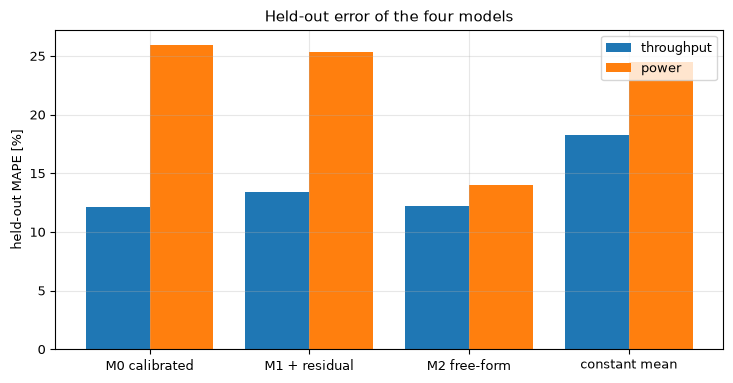

In [8]:
# Bar chart of the held-out MAPE of the four models for the throughput and for the power
fig, ax = plt.subplots()
x = np.arange(len(models))
ax.bar(x - 0.2, [score["tph", m] for m in models], 0.4, label="throughput")
ax.bar(x + 0.2, [score["kW", m] for m in models], 0.4, label="power")
ax.set_xticks(x, ["M0 calibrated", "M1 + residual", "M2 free-form", "constant mean"])
ax.set_ylabel("held-out MAPE [%]")
ax.set_title("Held-out error of the four models")
ax.legend()
fig.tight_layout()
plt.show()

For the throughput the calibrated model M0 scores 12.09 percent against 18.29 percent for the constant mean, a reduction of 33.9 percent, and the bounded-residual model M1 is worse than M0, 13.45 percent, so the residual brings nothing out of sample; the free-form regression M2, with three coefficients and no physics, is at 12.18 percent, as good as the physics within 0.1 points. For the power the calibrated model is at 25.94 percent against 24.48 percent for the mean, 6.0 percent worse than guessing the mean, and M1 at 25.37 percent is no better in substance. The free-form regression is the best of the four on the power, 14.03 percent, because the measured power tracks the setting and a regression on the setting follows it, while the Bond-driven form cannot. The clip acts in none of the ten throughput folds and in two of the ten power folds (printed above). The figure shows the ordering; the bars of the power show a physics model that loses to a constant, and one without physics that wins.

**Step 5, the control over many seeds.** The label-shuffle control fits the residual model to permuted measurements: the residual that M1 learns from the true labels is replaced by one learned from labels with no relation to the surveys, and the result is added to M0 and clipped in the same way. The control therefore tests the residual model, not the calibrated model: it asks how often a residual that knows nothing improves M0 by chance, and so how much a real residual would have to improve it to be believed. With ten points one draw says little, so the cell repeats the control for 200 seeds (the pipeline's committed document holds a single one, seed 42) and records the held-out error of the shuffled model each time. Each target draws its permutation from its own stream, as CrusherCal does (seed for the throughput, seed plus 1 for the power).

In [9]:
# The label-shuffle control: M0 plus a ridge residual fitted to permuted labels, 200 seeds and the seed 42
seeds = [42] + list(range(1, 201))
control = {"tph": [], "kW": []}
for seed in seeds:
    for offset, key in enumerate(targets):
        y, base = targets[key], pred[key, "M0"]
        permuted = y.copy()
        np.random.default_rng(seed + offset).shuffle(permuted)
        fits = [loo.fit_residual(features, base, permuted, rows, i, resid_target=permuted - base).clipped
                for i, rows in enumerate(folds)]
        control[key].append(loo.mape(y, base + np.array(fits)))
for key in targets:
    print(f"{key:4s} committed seed 42: {control[key][0]:6.2f} %")

tph  committed seed 42:  25.04 %
kW   committed seed 42:  40.19 %


The cell summarises the 200 seeds: the distribution of the shuffled model's error and the seeds in which it beats M0 and M1.

In [10]:
# Distribution of the shuffle control over the 200 seeds, and the seeds in which it beats M0 and M1
for key in targets:
    values = np.array(control[key][1:])
    beats_m0, beats_m1 = int((values < score[key, "M0"]).sum()), int((values < score[key, "M1"]).sum())
    print(f"{key:4s} shuffle control: mean {values.mean():6.2f} %", end=", ")
    print(f"min {values.min():6.2f} %, max {values.max():6.2f} %")
    print(f"     seeds beating M0: {beats_m0} of 200 | seeds beating M1: {beats_m1} of 200")

tph  shuffle control: mean  18.36 %, min  10.45 %, max  25.76 %
     seeds beating M0: 5 of 200 | seeds beating M1: 17 of 200
kW   shuffle control: mean  32.19 %, min  19.08 %, max  42.00 %
     seeds beating M0: 21 of 200 | seeds beating M1: 16 of 200


The figure shows the 200 shuffled errors as a histogram for each target, with the held-out error of M0 and of M1 as vertical lines.

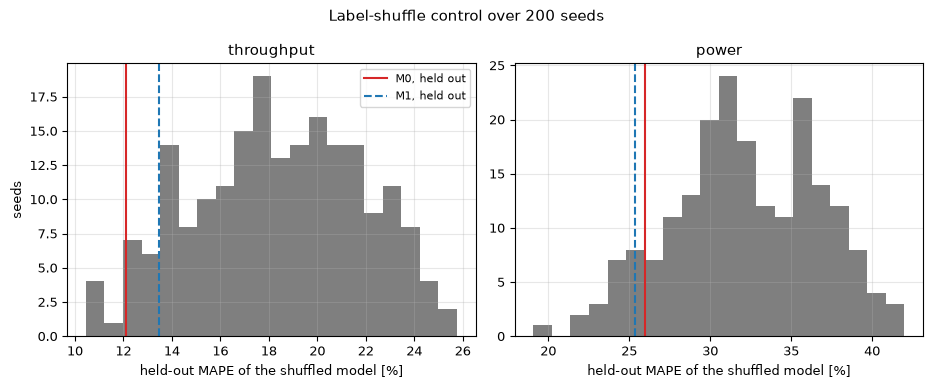

In [11]:
# Histogram of the shuffle-control error over 200 seeds, for each target, against M0 and M1 held out
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in ((left, "tph", "throughput"), (right, "kW", "power")):
    ax.hist(control[key][1:], bins=20, color="tab:grey")
    ax.axvline(score[key, "M0"], color="tab:red", lw=1.5, label="M0, held out")
    ax.axvline(score[key, "M1"], color="tab:blue", lw=1.5, ls="--", label="M1, held out")
    ax.set_xlabel("held-out MAPE of the shuffled model [%]")
    ax.set_title(label)
left.set_ylabel("seeds")
left.legend(fontsize=8)
fig.suptitle("Label-shuffle control over 200 seeds")
fig.tight_layout()
plt.show()

For the throughput, M0 sits at the far left of the histogram: only 5 of the 200 shuffled models are more accurate than it, so a residual that knows nothing almost never improves the calibrated model by chance. M1 is a different matter. At 13.45 percent it is beaten by 17 of the 200 shuffled models, so the residual learned from the true labels is hard to tell from one learned from noise, and the residual model has no demonstrated skill; this is the pre-registered null, reported as such. For the power, the residual model is again a null: 16 of the 200 shuffled models beat M1, about the same count as the 17 on the throughput. The 21 that beat M0 on the power only count how often a noise residual improves M0, which is no evidence on the skill of M0 itself. That rests on the baseline of step 4, where the throughput model clears the mean by 33.9 percent and the power model, at 25.94 against 24.48 percent, does not. The two histograms are the reason to run the control over many seeds: one draw at the committed seed 42, 25.04 and 40.19 percent, would have shown the shuffled model worse than M0 on both targets, and the distribution shows that the residual model M1 is a null on both targets, with 17 and 16 of 200 shuffled models beating it.

## Results

**Answer:** the held-out calibrated model beats the constant-mean baseline for the throughput, 12.09 against 18.29 percent, a reduction of 33.9 percent, and does not for the power, 25.94 against 24.48 percent, 6.0 percent worse than guessing the mean. The bounded-residual model M1 does not improve the throughput, 13.45 against 12.09 percent, and moves the power only from 25.94 to 25.37. The label-shuffle control over 200 seeds, a residual fitted to permuted labels, beats M0 in 5 seeds for the throughput and in 21 for the power, and beats M1 in 17 and 16: the residual model cannot be told from noise, while the throughput skill of M0 stands on the baseline and the power skill does not exist.

The first figure shows the held-out error of the four models on both targets and the second the control's distribution against M0 and M1. A validator would conclude that the product's throughput claim stands and its power claim does not, which is what the product reports; that one seed of a control is not a control; and that the control tests the residual model and not the backbone. The free-form regression's held-out power error, 14.03 percent, is lower than any model with physics, a finding that the product does not claim a use for: the measured power tracks the setting, which a regression on the setting captures and a Bond draw does not.

## Summary

The held-out comparison separates the two targets: the throughput model has skill that beats a baseline, the power model has none, and the free-form regression does better on the power because it reads the setting. The residual model is a null, and the label-shuffle control, run over 200 seeds, is what shows it; the control tests the residual, so the skill claims rest on the baseline. The numbers rest on ten surveys, and the control's own spread shows how coarse that is. Notebook 03 sets the paper's in-sample protocol beside this one, and notebook 04 states and measures the product's claim beyond it.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919